In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , OrdinalEncoder 
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report , confusion_matrix

In [64]:
X_df = pd.read_csv(r"C:\Users\DELL\Downloads\train (3).csv")
df = pd.read_csv(r"C:\Users\DELL\Downloads\test (3).csv")

In [65]:
X_df.head(30)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [66]:
X_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [67]:
X_df.duplicated().sum()

np.int64(0)

In [68]:
X_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [69]:
X_df.shape

(891, 12)

In [70]:
X_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [71]:
X = X_df.drop(["Survived","PassengerId"] , axis=1)
y = X_df["Survived"]

In [72]:
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
) 

In [73]:
for column in X_train.columns:
    if X_train[column].dtype in ["int64" , "float64"]:
         X_train[column] = X_train[column].fillna(X_train[column].mean())
    elif X_train[column].dtype == "object":
         X_train[column] = X_train[column].fillna(X_train[column].mode() [0])     

In [74]:
X_train.isnull().sum()

Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Ticket      0
Fare        0
Cabin       0
Embarked    0
dtype: int64

In [75]:
for column in X_test.columns:
    if X_test[column].dtype in ["int64" , "float64"]:
        X_test[column] = X_test[column].fillna(X_train[column].mean())
    elif X_test[column].dtype == "object":
        X_test[column] = X_test[column].fillna(X_train[column].mode()[0])

In [76]:
X_test.isnull().sum()

Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Ticket      0
Fare        0
Cabin       0
Embarked    0
dtype: int64

In [77]:
print(X_train.skew(numeric_only=True))
print(X_test.skew(numeric_only=True))

Pclass   -0.677419
Age       0.369103
SibSp     3.619385
Parch     2.695459
Fare      4.875066
dtype: float64
Pclass   -0.453067
Age       0.745114
SibSp     2.441650
Parch     2.912513
Fare      3.294218
dtype: float64


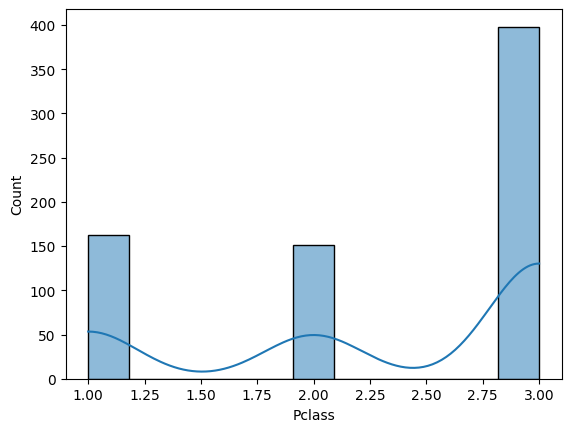

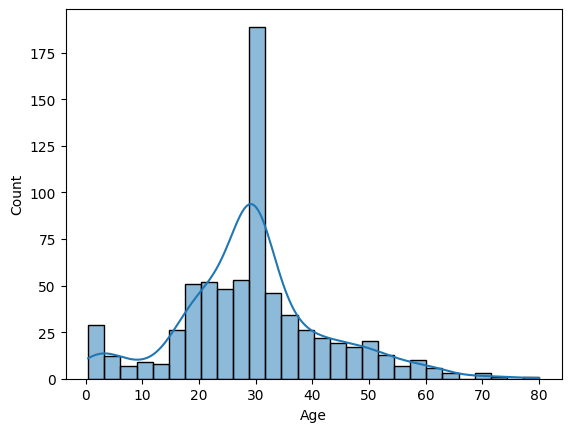

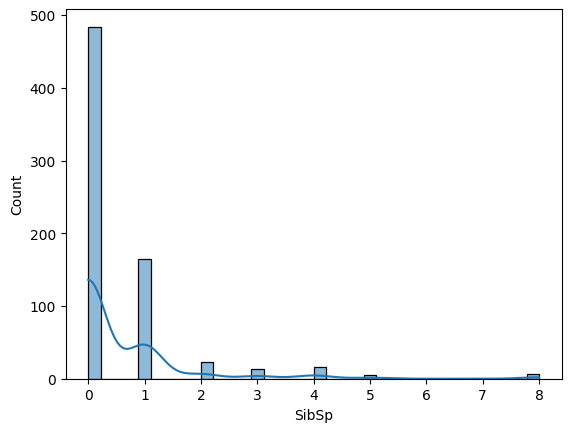

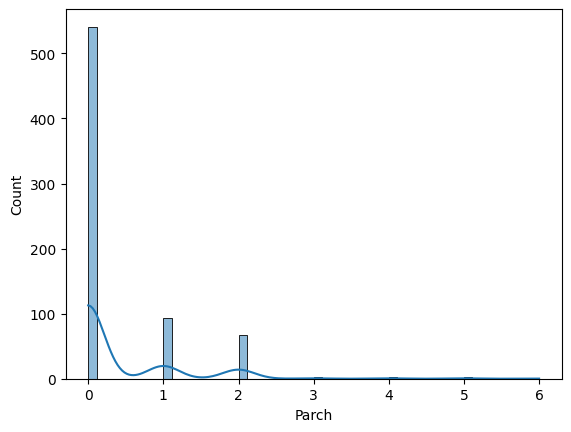

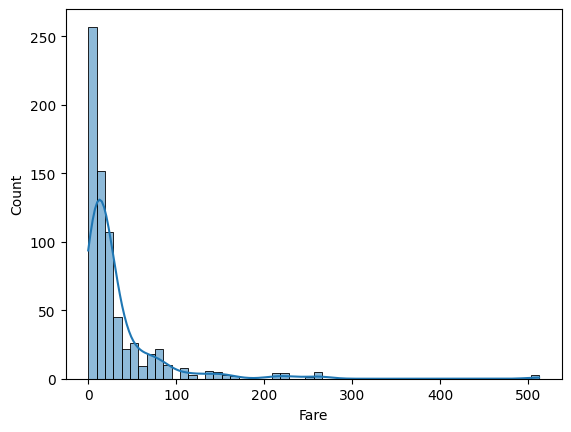

In [78]:
for name in X_train.columns:
    if X_train[name].dtype in ["int64" , "float64"]:
        sns.histplot(X_train[name] , kde=True)
        plt.show()

In [79]:
numerical_columns = X_train.select_dtypes(include=[np.number]).columns
print(f"numerical columns:{numerical_columns}")

numerical columns:Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')


In [80]:
Q1 = X_train[numerical_columns].quantile(0.25)
Q3 = X_train[numerical_columns].quantile(0.75)
IQR = Q3 - Q1



In [81]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [82]:
def Xtrain():
    for com in X_train[numerical_columns]:
        outliers_below = X_train[com] < lower_bound[com]
        outliers_above = X_train[com] > upper_bound[com]
        if outliers_below.any():
            print(f"outliers below lower bound in columns : {com}")
            print(X_train.loc[outliers_below , com])

        elif outliers_above.any():
            print(f"outliers above upper bound in columns : {com}")
            print(X_train.loc[outliers_above , com])
        else:
            print(f"no outliers in column : {com}")
            continue
def Xtest():
    for com in X_test[numerical_columns]:
        outliers_below = X_test[com] < lower_bound[com]
        outliers_above = X_test[com] > upper_bound[com]
        if outliers_below.any():
            print(f"outliers below lower bound in columns : {com}")
            print(X_test.loc[outliers_below , com])
        elif outliers_above.any():
            print(f"outliers above upper bound in columns : {com}")
            print(X_test.loc[outliers_above , com])
        else:
            print(f"no outliers in column : {com}")
            continue


Xtrain()                         

no outliers in column : Pclass
outliers below lower bound in columns : Age
7      2.00
305    0.92
172    1.00
164    1.00
381    1.00
644    0.75
530    2.00
340    2.00
827    1.00
479    2.00
16     2.00
469    0.75
119    2.00
297    2.00
183    1.00
788    1.00
386    1.00
824    2.00
803    0.42
755    0.67
642    2.00
205    2.00
831    0.83
Name: Age, dtype: float64
outliers above upper bound in columns : SibSp
813    4
542    4
409    3
7      3
164    4
24     3
182    4
176    3
787    4
324    8
68     4
88     3
278    4
634    3
261    4
59     5
341    3
50     4
792    8
180    8
171    4
16     4
480    5
229    3
374    3
119    4
386    5
863    8
233    4
846    8
824    4
850    4
85     3
159    8
642    3
683    5
27     3
726    3
201    8
686    4
71     5
Name: SibSp, dtype: int64
outliers above upper bound in columns : Parch
813    2
118    1
595    1
259    1
542    2
      ..
160    1
871    1
71     2
435    2
102    1
Name: Parch, Length: 171, dtype: int6

In [83]:
Xtest()

no outliers in column : Pclass
outliers below lower bound in columns : Age
78    0.83
Name: Age, dtype: float64
outliers above upper bound in columns : SibSp
485    3
819    3
63     3
266    4
541    4
Name: SibSp, dtype: int64
outliers above upper bound in columns : Parch
709    1
720    1
136    2
485    1
853    1
819    2
63     2
362    1
86     3
659    2
448    1
820    1
360    4
802    2
585    2
299    1
446    1
532    1
312    1
311    2
835    1
539    2
254    2
266    1
319    1
165    2
541    2
670    1
323    1
736    3
529    1
78     2
65     1
885    5
416    1
657    1
54     1
97     1
417    2
852    1
25     5
10     1
Name: Parch, dtype: int64
outliers above upper bound in columns : Fare
290     78.8500
120     73.5000
659    113.2750
820     93.5000
802    120.0000
585     79.6500
299    247.5208
72      73.5000
591     78.2667
311    262.3750
835     83.1583
319    134.5000
215    113.2750
291     91.0792
849     89.1042
527    221.7792
218     76.2917
275 

In [84]:
for com in X_train[numerical_columns]:
    X_train[com] = np.where(X_train[com] < lower_bound[com] , lower_bound[com] , np.where(X_train[com] > upper_bound[com] , upper_bound[com] , X_train[com]))

for coms in X_test[numerical_columns]:
    X_test[coms] = np.where(X_test[coms] < lower_bound[coms] , lower_bound[coms] , np.where(X_test[coms] > upper_bound[coms] , upper_bound[coms] , X_test[coms]))
        

In [85]:
Xtrain()
print("-" * 50)
Xtest()

no outliers in column : Pclass
no outliers in column : Age
no outliers in column : SibSp
no outliers in column : Parch
no outliers in column : Fare
--------------------------------------------------
no outliers in column : Pclass
no outliers in column : Age
no outliers in column : SibSp
no outliers in column : Parch
no outliers in column : Fare


In [86]:
# Feature Engineering on X_train
X_train["FamilySize"] = (
    X_train["SibSp"] + X_train["Parch"] + 1
)

X_train["IsAlone"] = (
    X_train["FamilySize"] == 1
).astype(int)

X_train["FarePerPerson"] = (
    X_train["Fare"] /
    X_train["FamilySize"].clip(lower=1)
)


# Feature Engineering on X_test
X_test["FamilySize"] = (
    X_test["SibSp"] + X_test["Parch"] + 1
)

X_test["IsAlone"] = (
    X_test["FamilySize"] == 1
).astype(int)

X_test["FarePerPerson"] = (
    X_test["Fare"] /
    X_test["FamilySize"].clip(lower=1)
)

In [87]:
cat_cols = X_train.select_dtypes(include="object").columns
enc = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train[cat_cols] = enc.fit_transform(X_train[cat_cols])
X_test[cat_cols] = enc.transform(X_test[cat_cols])

In [88]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 331 to 102
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pclass         712 non-null    float64
 1   Name           712 non-null    float64
 2   Sex            712 non-null    float64
 3   Age            712 non-null    float64
 4   SibSp          712 non-null    float64
 5   Parch          712 non-null    float64
 6   Ticket         712 non-null    float64
 7   Fare           712 non-null    float64
 8   Cabin          712 non-null    float64
 9   Embarked       712 non-null    float64
 10  FamilySize     712 non-null    float64
 11  IsAlone        712 non-null    int64  
 12  FarePerPerson  712 non-null    float64
dtypes: float64(12), int64(1)
memory usage: 77.9 KB


In [89]:
X_test.head()

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,IsAlone,FarePerPerson
709,3.0,-1.0,1.0,29.498846,1.0,0.0,-1.0,15.2458,50.0,0.0,2.0,0,7.62290
439,2.0,-1.0,1.0,31.000000,0.0,0.0,-1.0,10.5000,50.0,2.0,1.0,1,10.50000
840,3.0,-1.0,1.0,20.000000,0.0,0.0,-1.0,7.9250,50.0,2.0,1.0,1,7.92500
720,2.0,-1.0,0.0,6.000000,0.0,0.0,128.0,33.0000,50.0,2.0,1.0,1,33.00000
39,3.0,-1.0,0.0,14.000000,1.0,0.0,154.0,11.2417,50.0,0.0,2.0,0,5.62085


In [90]:
print(y_train.value_counts())
print(y_test.value_counts())

Survived
0    444
1    268
Name: count, dtype: int64
Survived
0    105
1     74
Name: count, dtype: int64


In [91]:
stnd = StandardScaler()
X_train_stnd = stnd.fit_transform(X_train)
X_test_stnd = stnd.transform(X_test)

In [92]:
list_acc = {}

models = {
    "logistic_regression" : LogisticRegression(max_iter=2000,
                                               C=1.0),
    "Decision_tree" : DecisionTreeClassifier(
        max_depth=7,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ),
    "Random_Forest" : RandomForestClassifier(
        n_estimators=150,
        max_depth=5,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ),
    "KNN" : KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    )
}

for name , model in  models.items():
    model.fit(X_train_stnd,y_train)
    y_pre = model.predict(X_test_stnd)
    acc = accuracy_score(y_test , y_pre)
    print(f"accuracy_score {name}: {acc}")
    list_acc[name] = acc

    print(f"\nClassification Report {name}:")
    print(classification_report(y_test, y_pre ))

    print(f"Confusion Matrix {name}:")
    print(confusion_matrix(y_test, y_pre))

acc_befor = pd.DataFrame({
    "acc" : list_acc
})
print(acc_befor)

    

accuracy_score logistic_regression: 0.8156424581005587

Classification Report logistic_regression:
              precision    recall  f1-score   support

           0       0.84      0.85      0.84       105
           1       0.78      0.77      0.78        74

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179

Confusion Matrix logistic_regression:
[[89 16]
 [17 57]]
accuracy_score Decision_tree: 0.8100558659217877

Classification Report Decision_tree:
              precision    recall  f1-score   support

           0       0.85      0.82      0.83       105
           1       0.76      0.80      0.78        74

    accuracy                           0.81       179
   macro avg       0.80      0.81      0.81       179
weighted avg       0.81      0.81      0.81       179

Confusion Matrix Decision_tree:
[[86 19]
 [15 59]]
accuracy_score Random_Forest: 0.8212290502793296

Cl